# 3Gyr Escaped Asteroid Analysis mc_pm6_3 
This notebooks is in preparation for the 3Gyr analysis and the new luthera family dataframe that includes more orbital information.

The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. 

This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 


In [1]:
import datetime as datetime
from pathlib import Path

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^9 ~ yr$]'

project_dir = Path('../../asteroid_data/mc_pm6_3/')

In [2]:
# Read the escaped asteroids file
ea_mmc3 = pd.read_hdf(project_dir / 'escaped_asteroids.h5')

# Strip the spaces out of the names of the asteroids
ea_mmc3['ast_name'] = [x.replace(' ','') for x in ea_mmc3.ast_name]

ea_mmc3.describe()

,particle_number,parameter,parameter_value,integration_year,min_val,max_val
count,22372.000000,22372.000000,22372.000000,2.237200e+04,22372.000000,22372.000000
mean,9.242893,6.733193,2.481881,1.763013e+09,0.339720,5.189682
std,0.814636,0.746258,5.762546,1.771735e+09,1.364254,10.009929
min,8.000000,6.000000,0.000000,1.000000e+04,-153.251723,0.340019
25%,9.000000,6.000000,0.341049,2.959772e+08,0.000000,0.749257
50%,9.000000,7.000000,0.389173,1.077054e+09,0.000000,1.115677
75%,10.000000,7.000000,0.781697,2.876264e+09,0.056549,3.230767
max,10.000000,8.000000,78.797254,6.283185e+09,3.905760,78.797254


In [3]:
print(f"Mars/Ceres Mercurious escaped test-particles:{(ea_mmc3.ast_name+ea_mmc3['vectors']).nunique()}")


Mars/Ceres Mercurious escaped test-particles:12436


In [4]:
new_fam_dir = Path('../../luthera_ast/')
plot_dir = project_dir / 'plots'

luth_proper_h5 = new_fam_dir / 'luther_proper.h5'
luth_fam = pd.read_hdf(luth_proper_h5)

luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

mag_h = 17
p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
luth_fam = luth_fam.set_index('ast_name')
luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.0,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,62.636725,163.961034,-74.485114,259.071526,-10.0,0.329816,18.897053,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.426461,57.980031,1.524164,752.086762,0.0,0.006072,0.347883,3.757710
min,9.480000,3.172780,0.106420,0.312013,61.765176,85.871008,-79.056097,5.500000,-10.0,0.317312,18.180615,1.752546
25%,15.620000,3.196843,0.117742,0.320017,62.306345,118.604830,-75.573336,29.200000,-10.0,0.325747,18.663932,2.829238
50%,16.390000,3.207515,0.123102,0.323137,62.653273,146.082211,-74.454953,82.950000,-10.0,0.329043,18.852771,3.561800
75%,16.890000,3.219394,0.129977,0.327705,62.966784,194.958434,-73.310560,250.000000,-10.0,0.333874,19.129562,5.077729
max,17.930000,3.238196,0.144674,0.340954,63.701778,361.322776,-71.181669,10000.000000,-10.0,0.347932,19.935032,85.836005


In [5]:
old_luth_h5 = '../../asteroid_data/luthera_family.h5'

old_luth_fam = pd.read_hdf(old_luth_h5)
old_luth_fam = old_luth_fam.set_index('ast_name')
old_luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P
count,878.000000,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863
std,0.987079,0.014558,0.008572,0.005743
min,9.480000,3.172780,0.106420,0.312013
25%,15.620000,3.196843,0.117742,0.320017
50%,16.390000,3.207515,0.123103,0.323137
75%,16.890000,3.219394,0.129976,0.327705
max,17.930000,3.238196,0.144674,0.340954


## Data issues !!!
The proper elements (from afp.num.pro.txt and afp.mult.pro.txt) were merged into the family data (afp.fam.members.txt)
to provide the perihelion an nodal precessions (g and s).

We now have unmatched asteroids coming back from the simulations as they were run with the old asteroid designations.

From the afp.fam.members.txt dated 2023AUG08

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
|  2017AC51 |  17.41   |   3.172780   |   0.120229   |   0.321580   |   1303 |

From the afp.fam.members.txt dated 2023FEB27
| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
| 2010VV146  |  17.41   |   3.172780   |   0.120229   |   0.321580    |  1303 |


From the afp.mult.pro.txt dated 2023AUG09

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | n | g | s | lyap time | My Int Time |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2017AC51  |   17.41  | 3.1727797 | 0.1202292 | 0.3215795  | 63.701778  |  85.871008  | -71.650735  |     14.9  |  -10 |
| 2010VV146  |  17.83  | 2.8051083 | 0.1852427 | 0.0790516  | 76.607069  |  68.027468  | -72.775633   |   243.9   | -10 |

There are 


In [6]:
# Extract the unique ast_names
family_asts = luth_fam.index.unique()
# Extract the unique ast_names
old_family_asts = old_luth_fam.index.unique()

# get the list of asteroids that remained the same
in_common = family_asts.intersection(old_family_asts)

# Find the ones that are not in both (these are the duplicates)
old_missing = old_luth_fam.index.difference(in_common)
new_missing = luth_fam.index.difference(in_common)

# Sort the values by semi major axis and eccentricity to line up the asteroids with the same values
old_sort = old_luth_fam[old_luth_fam.index.isin(old_missing)].sort_values(['a_P','e_P'])
new_sort = luth_fam[luth_fam.index.isin(new_missing)].sort_values(['a_P','e_P'])

name_converter = [ (x[1], x[0]) for x in zip(list(new_sort.index),list(old_sort.index))]

#print(name_converter)
for convert in name_converter:
    print(f'changing {convert[0]} to {convert[1]}')
    ea_mmc3.loc[(ea_mmc3.ast_name==convert[0]),'ast_name'] = convert[1]

ea_mmc3 = ea_mmc3.set_index('ast_name')

changing 2010VV146 to 2017AC51
changing 2006SW146 to 2010ET174
changing 2012AE37 to 2019JK107
changing 2007ES241 to 2011ES49
changing 2009SN2 to 2015MD194
changing 2009BN211 to 2015BL268
changing 2006US157 to 2010LV19
changing 2006UA386 to 2010HU44
changing 2011UB33 to 2018NG22
changing 2020BV10 to 2016CF331
changing 2010TE73 to 2016SC30
changing 2019GZ8 to 2015XZ150
changing 2002GM31 to 2017FD74
changing 2010FT39 to 2016AJ362
changing 2014WJ348 to 2014YJ58
changing 2016CZ173 to 2012TZ214
changing 2014LM34 to 2008WJ65
changing 2015BE248 to 2016CJ239
changing 2011SS321 to 2018FE48
changing 2005UM306 to 2007UE70
changing 2012UG127 to 2020TG54
changing 2011SF345 to 2018AC58
changing 2008HJ32 to 2014ET213
changing 2005XQ45 to 2008GP174
changing 2005YY288 to 2008SF343
changing 1998WE35 to 2016EQ53
changing 2016QY46 to 2014KA25
changing 2008VE103 to 2014UA268
changing 2006SL295 to 2010BY98
changing 2008UQ125 to 2014SL394
changing 2002RC253 to 2017HT43
changing 2015TM184 to 2008VV92
changing 

In [7]:
escaped_asts = ea_mmc3.index.unique()
print(f'Checking that all the escaped asts {len(escaped_asts)} = {len(luth_fam[luth_fam.index.isin(escaped_asts)==True])}')

Checking that all the escaped asts 478 = 478


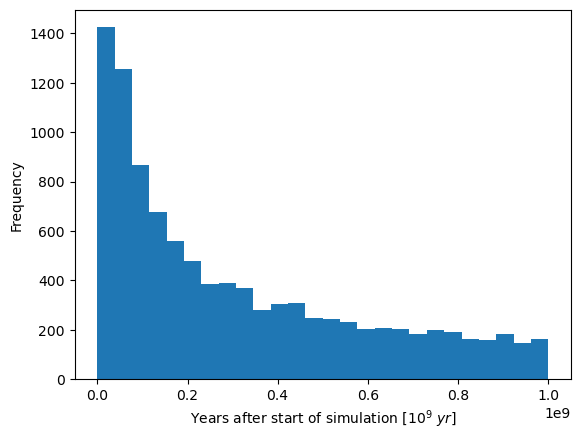

In [9]:
escapee_years = ea_mmc3.loc[ea_mmc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
plt.hist(escapee_years.integration_year, bins='auto')
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)
plt.show()

In [13]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')
mean_escape['vec_count'] = ey_years.vectors.count()

print(escapee_years.head())

print(mean_escape.head())

                         vectors  integration_year
ast_name                                          
2010FZ105  XcpYcpZcmVXcpVYcmVZcm      6.605666e+08
2013YE129  XcmYcmZcpVXcpVYcpVZcm      6.249631e+08
2018AR6    XcmYcmZcpVXcpVYcpVZcm      6.251631e+08
2015BO272  XcmYcmZcmVXcmVYcpVZcm      3.314342e+08
2019SQ13   XcmYcmZcmVXcmVYcpVZcm      1.917205e+08
          integration_year  vec_count
ast_name                             
104287        7.525757e+08          7
107448        8.575860e+08          1
111798        5.415549e+08          1
117224        4.624279e+08         26
121831        1.552029e+08         43


In [14]:
counts, bins = np.histogram(mean_escape.vec_count, 4)
mean_escape['quartiles'] = np.digitize(mean_escape.vec_count, bins)

In [19]:
luth_fam['integration_year'] = mean_escape.integration_year
luth_fam['quartiles'] = mean_escape.quartiles

luth_fam = luth_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
luth_fam['graph_symbol'] = '.'
luth_fam.loc[luth_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(luth_fam[luth_fam['integration_year']!=0])

luth_fam

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005,0.000000e+00,NaN,.
11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642,0.000000e+00,NaN,.
16794,13.45,3.229767,0.120773,0.321221,62.006408,267.491465,-76.751030,87.7,-10,0.327018,18.736764,13.793342,5.235426e+08,2.0,o
17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531,7.782782e+08,1.0,o
26558,13.15,3.194646,0.115763,0.319342,63.032408,116.103022,-72.503135,27.1,-10,0.325035,18.623155,15.836875,0.000000e+00,NaN,.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021TA55,17.17,3.194082,0.114092,0.317706,63.048004,115.703831,-72.437569,53.8,-10,0.323309,18.524232,2.486964,0.000000e+00,NaN,.
2021TZ86,17.04,3.199622,0.138950,0.332601,62.884899,122.499167,-74.946763,625.0,-10,0.339060,19.426734,2.640399,2.068090e+08,4.0,o
2021UJ60,17.20,3.194881,0.135663,0.334094,63.027298,111.565516,-73.689163,24.4,-10,0.340644,19.517454,2.452842,4.677810e+08,1.0,o


In [17]:
def flash_plot(ax, ast_data, y_column, x_column='a_P'):
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            stab = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            norm_vecs = m_fam['quartiles']*40
            colour_values = m_fam['integration_year']
            esc = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='black', marker=graph_symbol, 
                c=colour_values, cmap = cm_yr, s=norm_vecs, label='Quartile')
                
            cb = plt.colorbar(esc, label=xlabel_time, location='bottom')
    
    esc_elements = esc.legend_elements("sizes", num=4)
    stab_elements = stab.legend_elements("sizes", num=1)
        
    plt.legend(handles = stab_elements[0] + esc_elements[0], 
               labels=['Stable', '<25% Clones', '25-50% Clones','51-75% Clones', '>75% Clones'],
               bbox_to_anchor=(1.0, 1.0))


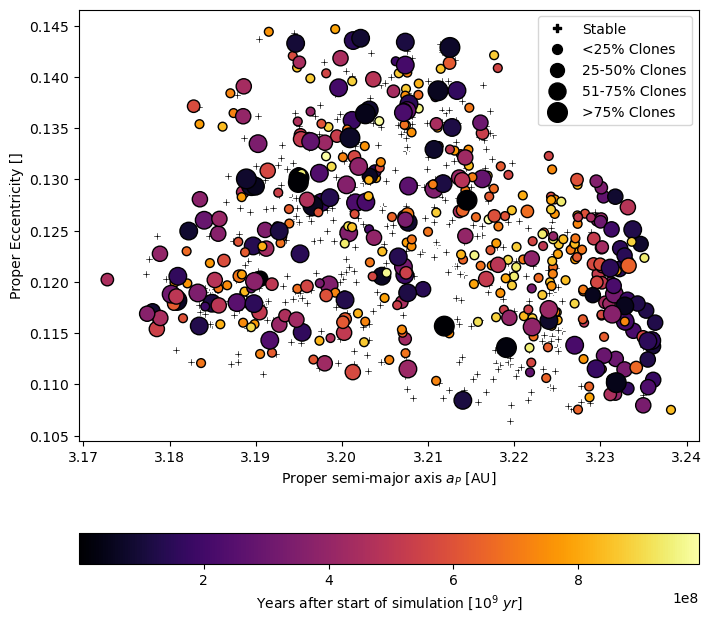

In [20]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'e_P')

plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

In [21]:
luth_fam[luth_fam.a_P <= 3.175]

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,,,,,
2017AC51,17.41,3.17278,0.120229,0.32158,63.701778,85.871008,-71.650735,14.9,-10,0.327397,18.758473,2.22674,4.570997e+08,2.0,o


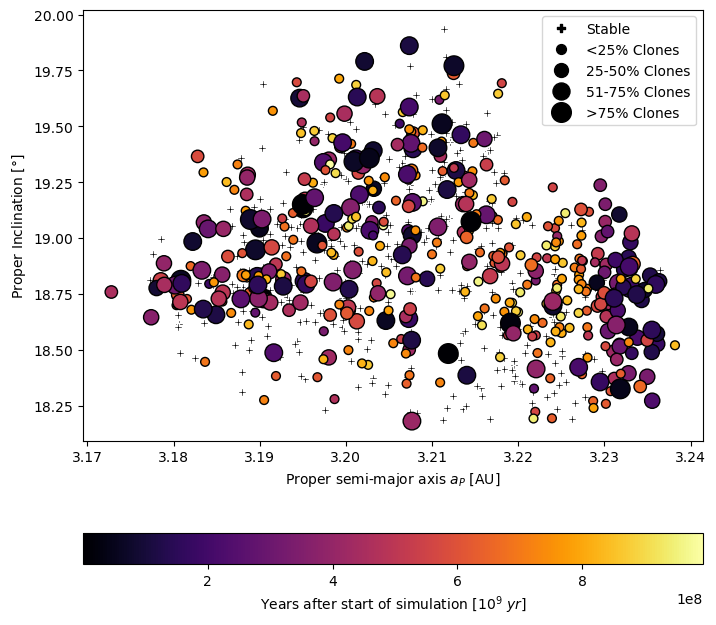

In [22]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

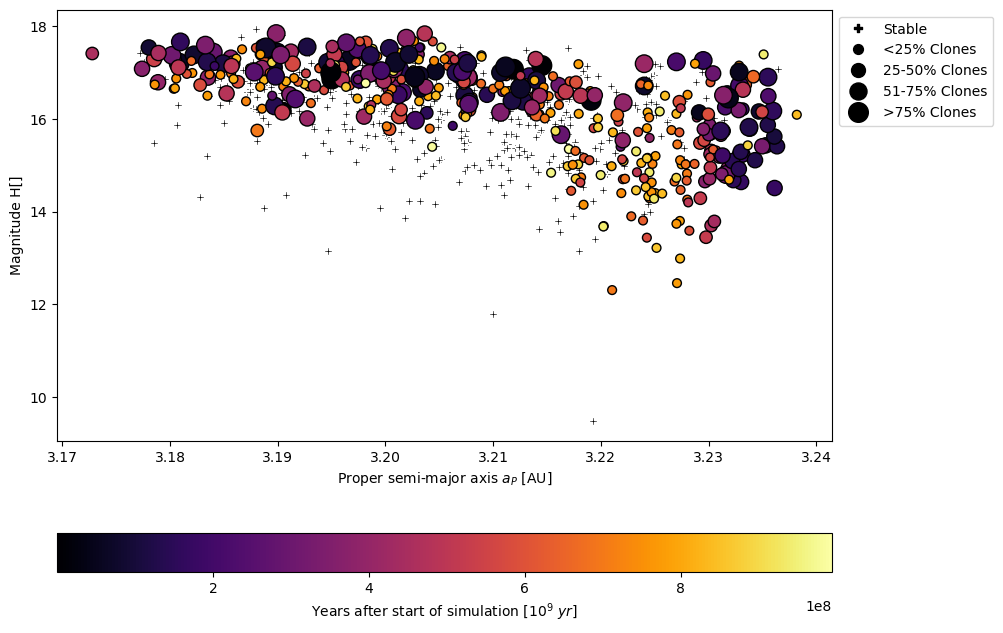

In [23]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'abs_mag')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude H[]")
plt.show()

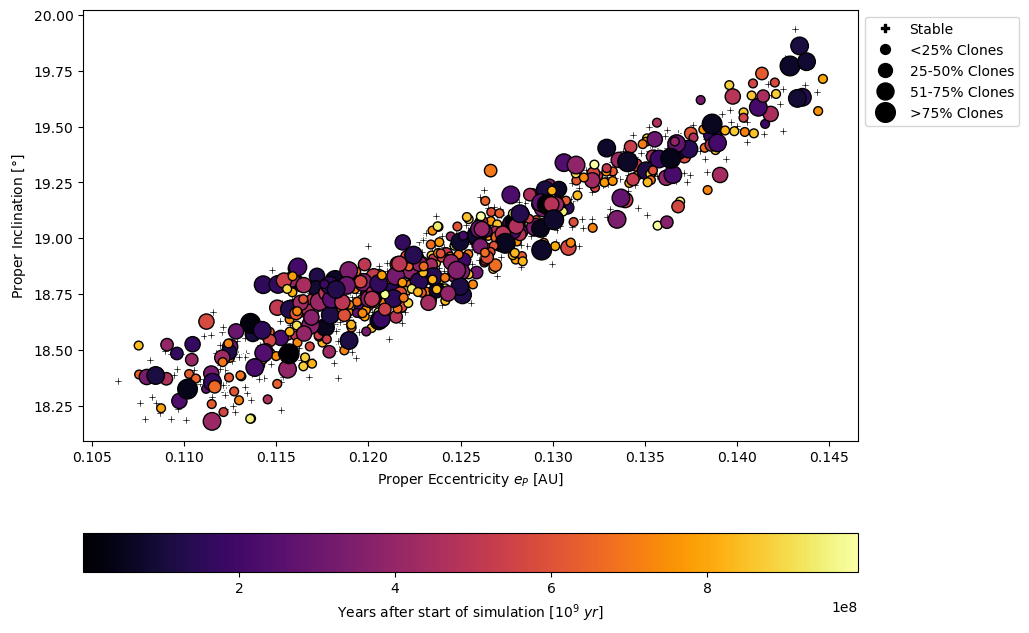

In [24]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg', 'e_P')
    
plt.xlabel("Proper Eccentricity $e_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

In [25]:
def hist_ratio(data, col_name, x_label):
    stable_cnts, bins = np.histogram(data[data.integration_year == 0][col_name],bins='auto')  
    escp_cnts, bins = np.histogram(data[data.integration_year != 0][col_name],bins=bins)
    ratio = ((stable_cnts)/(stable_cnts+escp_cnts+1.0e-40))*100

    fig = plt.figure(figsize=(8, 8))
    ax0 = plt.subplot(111)
    ax1 = ax0.twinx()
    ax0.hist([data[data.integration_year == 0][col_name], 
                  data[data.integration_year != 0][col_name]], bins=bins, stacked=True)
    ax0.set_ylabel("Frequency")
    ax0.set_xlabel(x_label)
    ax0.legend(labels=['Stable', 'Escaped'])


    ax1.plot(bins[:-1]+(bins[1]-bins[0])/2,ratio, c='grey', marker='+')
    ax1.set_ylim(0,100)
    ax1.set_ylabel("Asteroid Stability [%]")
    plt.show()
    

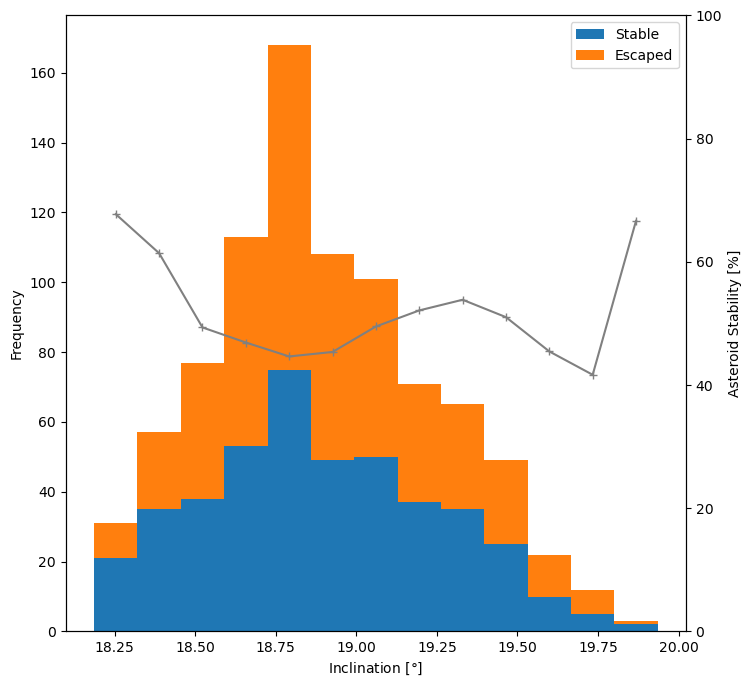

In [26]:
hist_ratio(luth_fam, 'ideg', "Inclination [$\degree$]")

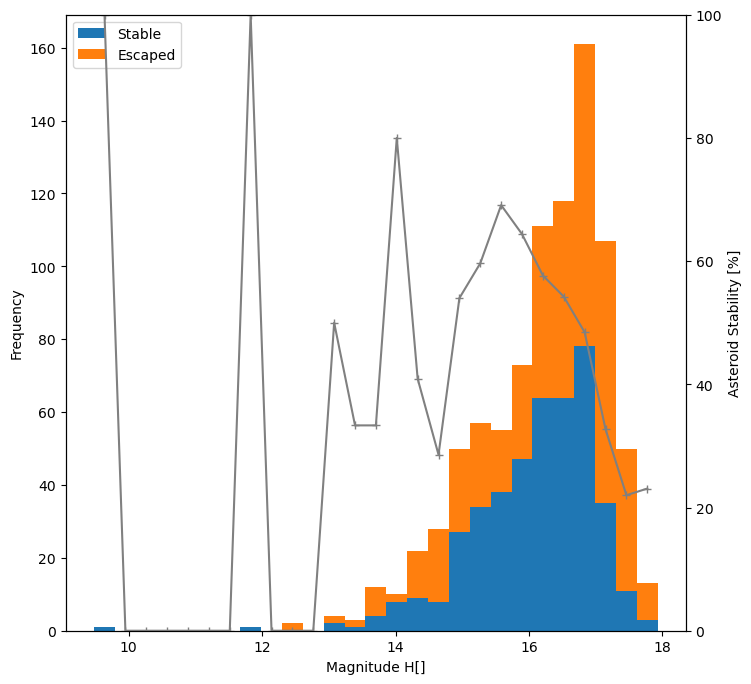

In [27]:
hist_ratio(luth_fam, 'abs_mag', "Magnitude H[]")

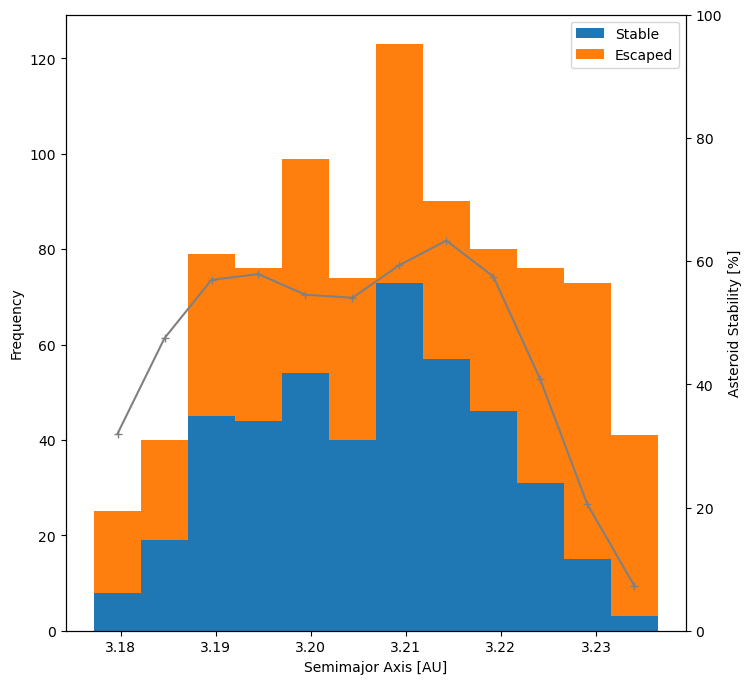

In [28]:
hist_ratio(luth_fam, 'a_P', "Semimajor Axis [AU]")

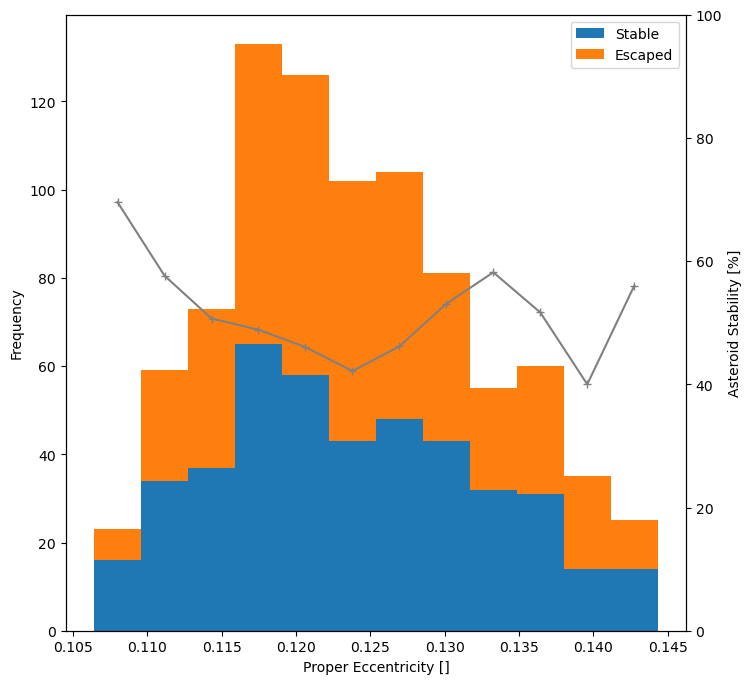

In [29]:
hist_ratio(luth_fam, 'e_P', "Proper Eccentricity []")

In [30]:
luth_fam.head()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005,0.000000e+00,NaN,.
11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642,0.000000e+00,NaN,.
16794,13.45,3.229767,0.120773,0.321221,62.006408,267.491465,-76.751030,87.7,-10,0.327018,18.736764,13.793342,5.235426e+08,2.0,o
17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531,7.782782e+08,1.0,o
26558,13.15,3.194646,0.115763,0.319342,63.032408,116.103022,-72.503135,27.1,-10,0.325035,18.623155,15.836875,0.000000e+00,NaN,.


In [34]:
ea_mmc3.head()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year,min_val,max_val
ast_name,,,,,,,,
2010FZ105,XcpYcpZcmVXcpVYcmVZcm,04171,10,6,4.257508,4.150462e+09,0.000000,4.257508
2010FZ105,XcpYcpZcmVXcpVYcmVZcm,04171,10,7,0.348465,3.494433e+09,0.000000,0.944321
2010FZ105,XcpYcpZcmVXcpVYcmVZcm,04171,10,8,0.790239,4.150462e+09,0.000000,0.790239
2013YE129,XcmYcmZcpVXcpVYcpVZcm,15194,9,6,15.418948,3.926759e+09,2.654812,15.418948
2018AR6,XcmYcmZcpVXcpVYcpVZcm,15194,10,6,0.000000,3.928016e+09,0.000000,2.714974
